# TF-IDF + SVM untuk deteksi komentar promosi judi daring

Eksperimen **Aidan Ismail** untuk JudiScope. Alurnya mengikuti notebook Bayesian
dan ANN: gunakan data bersih dan manifest bersama, pilih konfigurasi dari validation,
refit pada train + validation, lalu evaluasi pada test asli.

Kita membandingkan dua skenario SVM: data asli saja dan data asli dengan tambahan
1.066 komentar sintetis saat fitting. Semua hasil disimpan di `outputs/svm/`.
Notebook ini dapat dijalankan dari awal melalui **Run All**, tanpa repository SVM terpisah.

### Hasil eksekusi yang disertakan

Pada 1.787 komentar test asli, F1 kelas promosi adalah **0.980870** untuk data asli saja
dan **0.980017** dengan tambahan sintetis. Kedua konfigurasi memakai TF-IDF karakter
3–5 gram dan `C=10`; skenario asli saja dipilih dari validation.

Eksekusi tersimpan memakai Python 3.11.9 dan scikit-learn 1.4.2 melalui **IPython berurutan**.
Seluruh sel kode dieksekusi dan hasil disimpan. Transport kernel Jupyter belum diuji
pada lingkungan ini; notebook dapat dijalankan lewat VS Code/Jupyter dengan dependensi
pada `requirements.txt`.


## 1. Library dan parameter

TF-IDF mengubah komentar menjadi vektor; `LinearSVC` mempelajari batas keputusan.
Grid fitur dan aturan seleksi sama dengan protokol JudiScope. Parameter SVM
dipertahankan dari eksperimen awal: `C = 0.1, 1, 10`, seed 42, L2, dan squared hinge.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import hashlib
import json
import platform
import re
import unicodedata
import warnings

import joblib
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

SEED = 42
C_VALUES = [0.1, 1.0, 10.0]
FEATURES = {
    'word_1_2': {'analyzer': 'word', 'ngram_range': (1, 2)},
    'char_wb_3_5': {'analyzer': 'char_wb', 'ngram_range': (3, 5)},
}
TFIDF_OPTIONS = dict(min_df=2, max_features=40_000, sublinear_tf=True,
                     lowercase=False, norm='l2', use_idf=True, smooth_idf=True)
SVM_OPTIONS = dict(penalty='l2', loss='squared_hinge', dual='auto', tol=0.0001,
                   max_iter=10_000, class_weight=None, fit_intercept=True,
                   intercept_scaling=1, random_state=SEED)
SCENARIOS = ['original_only', 'with_synthetic']
LABEL_NAMES = ['0: nonjudi (pemetaan kerja)', '1: promosi judi (pemetaan kerja)']

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / 'dataset').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
assert (PROJECT_DIR / 'dataset').is_dir(), 'Jalankan notebook dari folder JudiScope.'

INPUTS = {
    'cleaned': PROJECT_DIR / 'outputs/cleaning/komentar_cleaned.csv',
    'manifest': PROJECT_DIR / 'outputs/bayesian/original_split_manifest.csv',
    'synthetic': PROJECT_DIR / 'outputs/augmentation/komentar_synthetic_only.csv',
}
EXPECTED_HASHES = {
    'cleaned': '5748b86c1d1d72c9e29023b8311e692f0fbebe3edc9fe556df6a5b4c75b3feb3',
    'manifest': '1512e44e643cfbf666895fadcba550fd17111a1caef9584825adcbd83a0b0781',
    'synthetic': '4ac721c4a2aa5da53aae12ff0a177f5a9a384b5c387aa481839ed67cf3002c0c',
}
OUT_DIR = PROJECT_DIR / 'outputs/svm'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def utc_now():
    return datetime.now(timezone.utc).isoformat()

try:
    shell_name = type(get_ipython()).__name__
except NameError:
    shell_name = ''
EXECUTION_MODE = ('jupyter_kernel' if shell_name == 'ZMQInteractiveShell'
                  else 'sequential_ipython' if shell_name else 'python_script')
STARTED_AT = utc_now()
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scipy': scipy.__version__,
            'sklearn': sklearn.__version__, 'matplotlib': plt.matplotlib.__version__,
            'joblib': joblib.__version__}

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'original_only': '#285E8E', 'with_synthetic': '#B77A18'}
pd.set_option('display.max_colwidth', 95)
display(pd.Series(VERSIONS, name='versi').to_frame())

,versi
python,3.11.9
numpy,1.26.4
pandas,3.0.3
scipy,1.17.1
sklearn,1.4.2
matplotlib,3.10.9
joblib,1.5.3


## 2. Baca data bersama

Masukan model hanya `komentar_processed`; targetnya `label`. `source_row` dipakai
untuk pencocokan, bukan sebagai fitur. Hash mengunci snapshot yang dipakai pada
eksperimen awal. Jika hash berbeda, periksa versi data sebelum melanjutkan.

Pemetaan kerja: `0 = nonjudi`, `1 = promosi judi`. Definisi label dan proses anotasi
sumber belum terverifikasi. Data berasal dari [Judi Online di Kaggle](https://www.kaggle.com/datasets/yaemico/judionline);
rincian sumber tersedia di [dataset/README.md](dataset/README.md).

In [2]:
for path in INPUTS.values():
    assert path.is_file(), f'{path} belum tersedia; jalankan tahap persiapan JudiScope.'
input_hashes = {name: sha256_file(path) for name, path in INPUTS.items()}
assert input_hashes == EXPECTED_HASHES, 'Snapshot input berbeda dari baseline bersama.'

original = pd.read_csv(INPUTS['cleaned'], dtype=str, keep_default_na=False, encoding='utf-8-sig')
manifest = pd.read_csv(INPUTS['manifest'], dtype=str, keep_default_na=False)
synthetic = pd.read_csv(INPUTS['synthetic'], dtype=str, keep_default_na=False, encoding='utf-8-sig')

assert original['source_row'].is_unique and original['source_row'].ne('').all()
assert manifest['source_row'].is_unique
assert set(original['source_row']) == set(manifest['source_row'])
assert set(manifest['split']) == {'train', 'validation', 'test'}
assert original['label'].isin(['0', '1']).all()
assert synthetic['label'].eq('1').all()
assert synthetic['is_synthetic'].str.lower().eq('true').all()
assert synthetic['data_origin'].eq('synthetic_template').all()
assert synthetic['synthetic_id'].is_unique
for frame in [original, synthetic]:
    assert frame['komentar_processed'].str.strip().ne('').all()
    assert frame['komentar_processed'].is_unique
assert set(original['komentar_processed']).isdisjoint(synthetic['komentar_processed'])

data = manifest.merge(original, on='source_row', how='left', validate='one_to_one', sort=False)
assert data['source_row'].tolist() == manifest['source_row'].tolist()
data['label'] = data['label'].astype(int)
synthetic['label'] = synthetic['label'].astype(int)
assert len(data) == 8934 and len(synthetic) == 1066
display(pd.DataFrame({'asal': ['asli bersih', 'sintetis'], 'jumlah': [len(data), len(synthetic)]}))

,asal,jumlah
0,asli bersih,8934
1,sintetis,1066


## 3. Ikuti pembagian dari manifest Bayesian

Notebook Bayesian membuat dan mengekspor manifest; notebook ANN dan SVM membacanya.
Data sintetis hanya masuk fitting pada skenario augmentasi. Validation dan test
selalu memakai komentar asli yang sama. Tidak ada pembagian acak baru di notebook ini.

In [3]:
parts = {name: data.loc[data['split'].eq(name)].copy().reset_index(drop=True)
         for name in ['train', 'validation', 'test']}
train, validation, test = [parts[name] for name in ['train', 'validation', 'test']]
assert (len(train), len(validation), len(test)) == (5360, 1787, 1787)
assert train['label'].value_counts().to_dict() == {0: 3610, 1: 1750}
for part in [validation, test]:
    assert part['label'].value_counts().to_dict() == {0: 1203, 1: 584}
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(parts[left]['source_row']).isdisjoint(parts[right]['source_row'])
    assert set(parts[left]['komentar_processed']).isdisjoint(parts[right]['komentar_processed'])

model_columns = ['komentar_processed', 'label']
training_sets = {
    'original_only': train[model_columns].copy(),
    'with_synthetic': pd.concat([train[model_columns], synthetic[model_columns]], ignore_index=True),
}
assert len(training_sets['with_synthetic']) == 6426
split_counts = pd.DataFrame({name: part['label'].value_counts()
                             for name, part in parts.items()}).T
split_counts.columns = ['label_0', 'label_1']
split_counts['total'] = split_counts.sum(axis=1)
display(split_counts)

,label_0,label_1,total
train,3610,1750,5360
validation,1203,584,1787
test,1203,584,1787


## 4. Pipeline TF-IDF dan LinearSVC

Setiap kandidat memakai pipeline baru, sehingga vocabulary dan IDF dipelajari
hanya dari data fitting kandidat tersebut. Kita menguji TF-IDF kata 1–2 gram dan
karakter `char_wb` 3–5 gram. Model yang belum konvergen harus diperiksa sebelum test.

In [4]:
def make_pipeline(feature_name, c_value):
    return Pipeline([
        ('tfidf', TfidfVectorizer(**FEATURES[feature_name], **TFIDF_OPTIONS)),
        ('svm', LinearSVC(C=float(c_value), **SVM_OPTIONS)),
    ])

def metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_1': float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'recall_1': float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'f1_1': float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=[0, 1], average='macro', zero_division=0)),
    }

def fit_checked(model, fit_data):
    start = perf_counter()
    with warnings.catch_warnings(record=True) as notices:
        warnings.simplefilter('always')
        model.fit(fit_data['komentar_processed'], fit_data['label'])
    elapsed = perf_counter() - start
    convergence = [str(n.message) for n in notices if issubclass(n.category, ConvergenceWarning)]
    assert not convergence, f'Model belum konvergen: {convergence}'
    assert list(model.classes_) == [0, 1]
    return float(elapsed)

## 5. Latih kandidat dan pilih melalui validation

Ada enam kandidat per skenario, dua belas keseluruhan. Seleksi memakai F1 kelas `1`,
lalu macro-F1. Jika masih seri, gunakan urutan fitur di atas lalu `C` terkecil;
seri antarskenario mengutamakan `original_only`. Test belum dinilai pada tahap ini.

In [5]:
tuning_records = []
for arm, fit_data in training_sets.items():
    for feature_name in FEATURES:
        for c_value in C_VALUES:
            candidate = make_pipeline(feature_name, c_value)
            fit_seconds = fit_checked(candidate, fit_data)
            pred = candidate.predict(validation['komentar_processed'])
            tuning_records.append({
                'experiment': arm, 'features': feature_name, 'C': c_value,
                'fit_rows': len(fit_data), 'fit_seconds': fit_seconds,
                'feature_count': len(candidate.named_steps['tfidf'].vocabulary_),
                'n_iter': int(np.max(candidate.named_steps['svm'].n_iter_)),
                'converged': True, **metrics(validation['label'], pred),
            })
assert len(tuning_records) == 12
tuning_results = pd.DataFrame(tuning_records)
feature_order = list(FEATURES)
best_per_arm = {}
for arm in SCENARIOS:
    candidates = [r for r in tuning_records if r['experiment'] == arm]
    best_per_arm[arm] = min(candidates, key=lambda r: (
        -r['f1_1'], -r['macro_f1'], feature_order.index(r['features']), r['C']))
selected_arm = min(SCENARIOS, key=lambda arm: (
    -best_per_arm[arm]['f1_1'], -best_per_arm[arm]['macro_f1'], SCENARIOS.index(arm)))
selection_locked_at = utc_now()
selection_before_test = json.dumps({'selected': selected_arm, 'best': best_per_arm}, sort_keys=True)
display(tuning_results[['experiment', 'features', 'C', 'f1_1', 'macro_f1', 'converged']].round(5))
print('Pilihan validation:', selected_arm)
display(pd.DataFrame(best_per_arm.values())[['experiment', 'features', 'C', 'f1_1', 'macro_f1']].round(5))

Pilihan validation: original_only


,experiment,features,C,f1_1,macro_f1,converged
0,original_only,word_1_2,0.1,0.92687,0.94731,True
1,original_only,word_1_2,1.0,0.95289,0.96562,True
2,original_only,word_1_2,10.0,0.94867,0.96247,True
3,original_only,char_wb_3_5,0.1,0.95714,0.96879,True
4,original_only,char_wb_3_5,1.0,0.98435,0.98846,True
5,original_only,char_wb_3_5,10.0,0.98531,0.98914,True
6,with_synthetic,word_1_2,0.1,0.93032,0.94957,True
7,with_synthetic,word_1_2,1.0,0.95575,0.96765,True
8,with_synthetic,word_1_2,10.0,0.95137,0.96443,True
9,with_synthetic,char_wb_3_5,0.1,0.95993,0.97078,True


,experiment,features,C,f1_1,macro_f1
0,original_only,char_wb_3_5,10.0,0.98531,0.98914
1,with_synthetic,char_wb_3_5,10.0,0.98363,0.98788


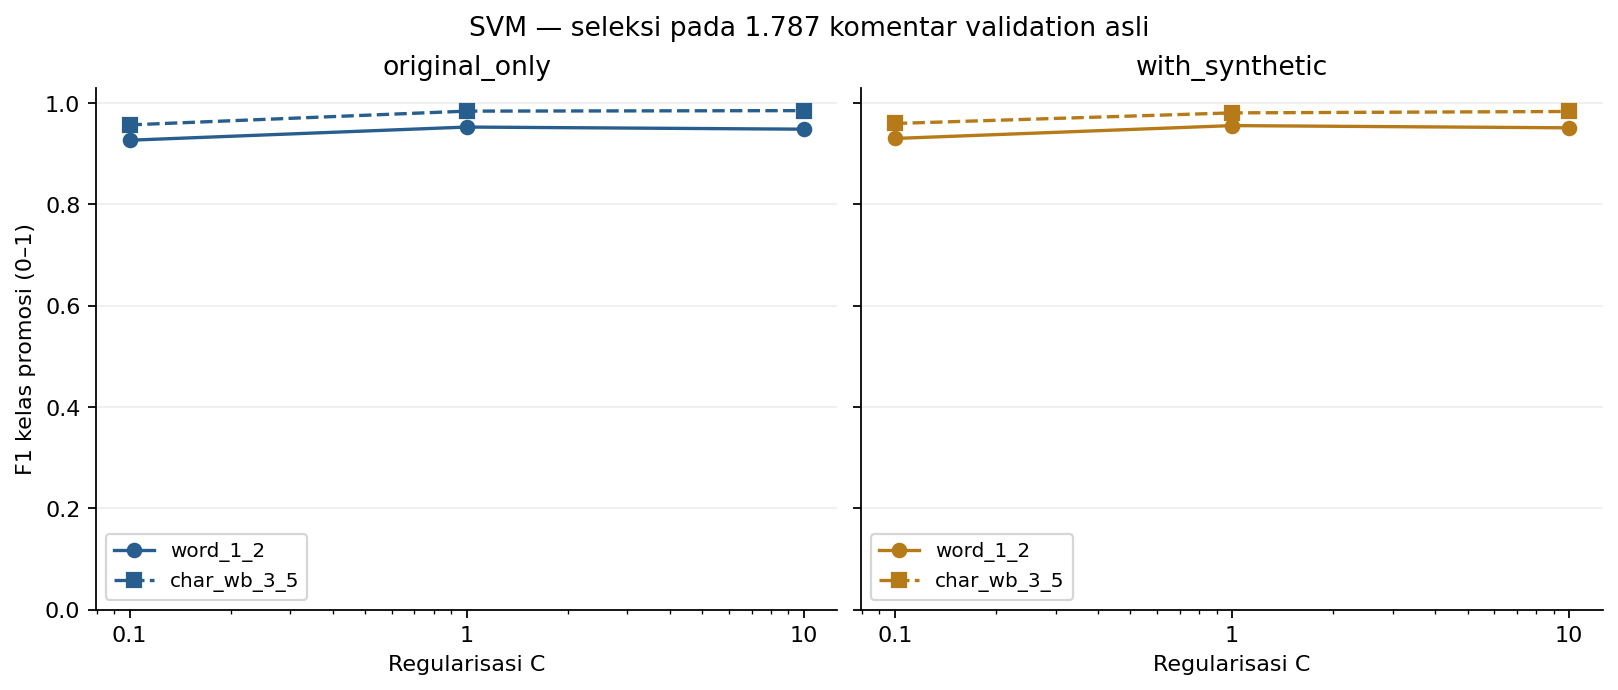

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True, constrained_layout=True)
for ax, arm in zip(axes, SCENARIOS):
    for feat, marker, linestyle in [('word_1_2', 'o', '-'), ('char_wb_3_5', 's', '--')]:
        subset = tuning_results.loc[tuning_results['experiment'].eq(arm) & tuning_results['features'].eq(feat)]
        ax.plot(subset['C'], subset['f1_1'], marker=marker, linestyle=linestyle,
                color=COLORS[arm], label=feat)
    ax.set(xscale='log', xlabel='Regularisasi C', title=arm, ylim=(0, 1.03))
    ax.set_xticks(C_VALUES, labels=['0.1', '1', '10'])
    ax.grid(axis='y', alpha=.2)
    ax.legend(fontsize=9)
axes[0].set_ylabel('F1 kelas promosi (0–1)')
fig.suptitle('SVM — seleksi pada 1.787 komentar validation asli')
fig.savefig(OUT_DIR / 'validation_scores.png', dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(OUT_DIR / 'validation_scores.png')))

## 6. Refit konfigurasi terpilih pada development

Setelah seleksi dikunci, buat pipeline baru untuk kedua skenario. TF-IDF ikut
dipelajari ulang pada 7.147 komentar train + validation; skenario augmentasi
menambahkan 1.066 sintetis sehingga total fitting menjadi 8.213. Test tetap terpisah.

In [7]:
development = pd.concat([train[model_columns], validation[model_columns]], ignore_index=True)
final_models, fit_times, final_fit_rows = {}, {}, {}
for arm in SCENARIOS:
    fit_data = development if arm == 'original_only' else pd.concat(
        [development, synthetic[model_columns]], ignore_index=True)
    assert len(fit_data) == (7147 if arm == 'original_only' else 8213)
    best = best_per_arm[arm]
    model = make_pipeline(best['features'], best['C'])
    fit_times[arm] = fit_checked(model, fit_data)
    final_models[arm] = model
    final_fit_rows[arm] = len(fit_data)
selected_model = final_models[selected_arm]
print('Refit selesai; konfigurasi dan skenario tetap mengikuti validation.')

Refit selesai; konfigurasi dan skenario tetap mengikuti validation.


## 7. Evaluasi pada test asli

Kedua skenario memakai 1.787 komentar test yang sama, terdiri dari 1.203 label `0`
dan 584 label `1`. Mayoritas selalu memprediksi label `0` sebagai baseline sederhana.
Margin SVM adalah **skor keputusan, bukan probabilitas**. Hasil test tidak digunakan
untuk mengganti parameter atau skenario terpilih.

In [8]:
assert json.dumps({'selected': selected_arm, 'best': best_per_arm}, sort_keys=True) == selection_before_test
test_evaluated_at = utc_now()
test_records, predictions, margins, reports, matrices = [], {}, {}, {}, {}
for arm in SCENARIOS:
    model = final_models[arm]
    start = perf_counter()
    pred = model.predict(test['komentar_processed'])
    prediction_seconds = float(perf_counter() - start)
    predictions[arm] = pred
    margins[arm] = model.decision_function(test['komentar_processed'])
    matrix = confusion_matrix(test['label'], pred, labels=[0, 1])
    tn, fp, fn, tp = [int(value) for value in matrix.ravel()]
    matrices[arm] = matrix.tolist()
    reports[arm] = classification_report(test['label'], pred, labels=[0, 1],
        target_names=LABEL_NAMES, output_dict=True, zero_division=0)
    test_records.append({'experiment': arm, **metrics(test['label'], pred),
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp, 'fit_rows': final_fit_rows[arm],
        'test_rows': len(test), 'refit_seconds': fit_times[arm],
        'test_predict_seconds': prediction_seconds})

dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(development), 1)), development['label'])
dummy_pred = dummy.predict(np.zeros((len(test), 1)))
test_records.append({'experiment': 'majority_baseline', **metrics(test['label'], dummy_pred),
    'tn': 1203, 'fp': 0, 'fn': 584, 'tp': 0, 'fit_rows': len(development),
    'test_rows': len(test), 'refit_seconds': None, 'test_predict_seconds': None})
test_results = pd.DataFrame(test_records)
display(test_results[['experiment', 'accuracy', 'precision_1', 'recall_1', 'f1_1', 'macro_f1']].round(6))
print('Pilihan sebelum test tetap:', selected_arm)

Pilihan sebelum test tetap: original_only


,experiment,accuracy,precision_1,recall_1,f1_1,macro_f1
0,original_only,0.987689,0.996466,0.965753,0.980870,0.985897
1,with_synthetic,0.987129,0.994709,0.965753,0.980017,0.985263
2,majority_baseline,0.673195,0.000000,0.000000,0.000000,0.402341


## 8. Confusion matrix dan metrik

Baris menunjukkan label rujukan, kolom menunjukkan prediksi. False positive adalah
label `0` yang diprediksi `1`; false negative adalah label `1` yang diprediksi `0`.
Warna skenario tetap konsisten dan nilai lengkap tersedia pada tabel di atas.

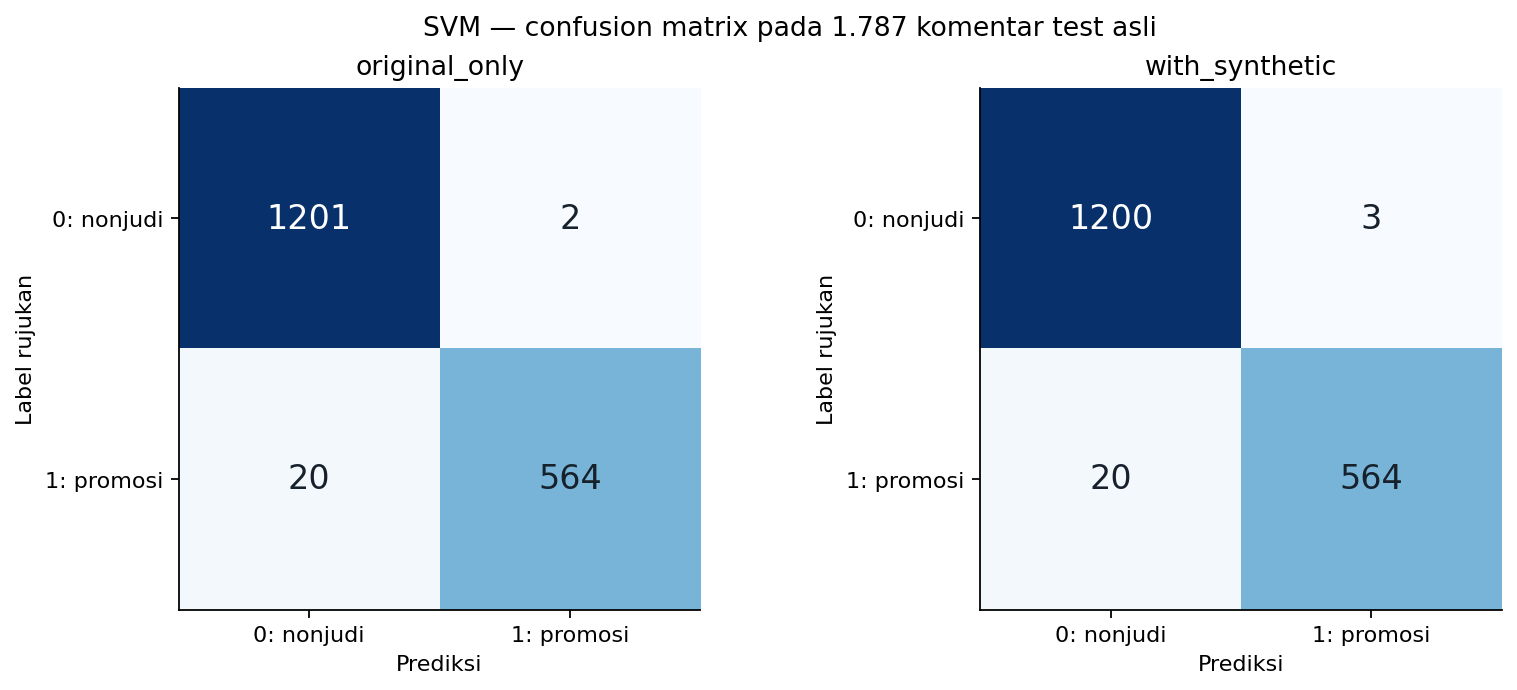

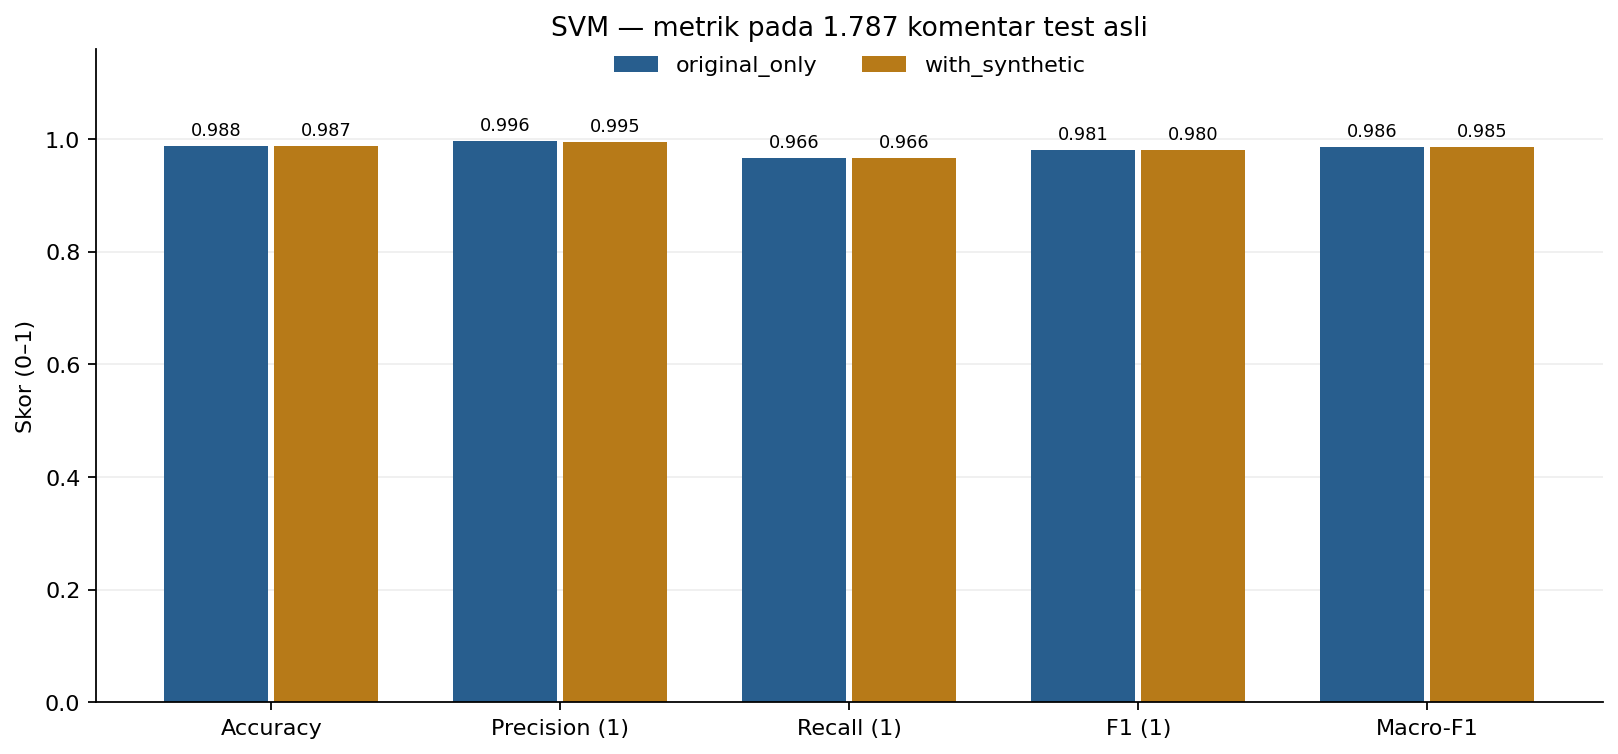

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
maximum = max(max(row) for matrix in matrices.values() for row in matrix)
for ax, arm in zip(axes, SCENARIOS):
    matrix = np.asarray(matrices[arm])
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=maximum)
    for (i, j), count in np.ndenumerate(matrix):
        ax.text(j, i, str(count), ha='center', va='center', fontsize=15,
                color='white' if count > maximum / 2 else '#17212B')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['0: nonjudi', '1: promosi'],
           yticklabels=['0: nonjudi', '1: promosi'], xlabel='Prediksi', ylabel='Label rujukan', title=arm)
fig.suptitle('SVM — confusion matrix pada 1.787 komentar test asli')
fig.savefig(OUT_DIR / 'confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(OUT_DIR / 'confusion_matrices.png')))

metric_columns = ['accuracy', 'precision_1', 'recall_1', 'f1_1', 'macro_f1']
fig, ax = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
x = np.arange(len(metric_columns))
for offset, arm in [(-.19, 'original_only'), (.19, 'with_synthetic')]:
    row = test_results.loc[test_results['experiment'].eq(arm)].iloc[0]
    bars = ax.bar(x + offset, [row[k] for k in metric_columns], width=.36,
                  color=COLORS[arm], label=arm)
    ax.bar_label(bars, labels=[f'{row[k]:.3f}' for k in metric_columns], padding=3, fontsize=8)
ax.set(xticks=x, xticklabels=['Accuracy', 'Precision (1)', 'Recall (1)', 'F1 (1)', 'Macro-F1'],
       ylim=(0, 1.16), ylabel='Skor (0–1)', title='SVM — metrik pada 1.787 komentar test asli')
ax.legend(loc='upper center', bbox_to_anchor=(.5, 1.02), ncol=2, frameon=False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.savefig(OUT_DIR / 'test_metrics.png', dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(OUT_DIR / 'test_metrics.png')))

## 9. Analisis kesalahan dan fitur

Format prediksi mengikuti Bayesian dan ANN: satu baris per komentar, dengan hasil
kedua skenario pada kolom terpisah. File kesalahan memuat model yang dipilih melalui
validation. Seluruh kesalahan skenario lainnya tetap dapat ditelusuri dari prediksi.

Koefisien positif mendorong keputusan ke kelas promosi, koefisien negatif ke kelas
nonjudi. Ini asosiasi dalam model TF-IDF, bukan penjelasan sebab-akibat atau probabilitas.

In [10]:
test_predictions = test[['source_row', 'komentar', 'komentar_processed', 'label']].copy()
for arm in SCENARIOS:
    test_predictions[f'pred_{arm}'] = predictions[arm]
    test_predictions[f'decision_score_{arm}'] = margins[arm]
error_mask = test['label'].ne(predictions[selected_arm])
errors = test_predictions.loc[error_mask].copy()
errors['error_type'] = np.where(errors['label'].eq(0), 'false_positive', 'false_negative')
display(errors['error_type'].value_counts().rename('jumlah').to_frame())
for kind in ['false_positive', 'false_negative']:
    print(kind)
    display(errors.loc[errors['error_type'].eq(kind),
        ['komentar', 'label', 'pred_' + selected_arm, 'decision_score_' + selected_arm]].head(5))

terms = selected_model.named_steps['tfidf'].get_feature_names_out()
coefficients = selected_model.named_steps['svm'].coef_[0]
assert len(terms) == len(coefficients)
feature_weights = pd.DataFrame({'fitur': terms, 'coefficient_1_vs_0': coefficients})
display(feature_weights.nlargest(8, 'coefficient_1_vs_0').round(4))

false_positive
false_negative


,jumlah
error_type,
false_negative,20
false_positive,2


,komentar,label,pred_original_only,decision_score_original_only
192,Belik cilok depan alfa 5k 🗿👍🏿,0,1,0.630470
1095,"sepeda udah ga maen , golf",0,1,0.476051


,komentar,label,pred_original_only,decision_score_original_only
163,"Tidak pernah merasa bosan sedikit pun bermain 𝐷𝑂R𝐴77, karena selalu ada inovasi dan kejutan!",1,0,-0.172383
262,wadidaw kren bgt yak depo 50 doan jd 2jt wwk💫💫,1,0,-0.695816
286,akari awetnya terbaik,1,0,-0.590455
290,buseettt bener,1,0,-0.986715
479,wajib coba sih coba mantep banget,1,0,-0.140819


,fitur,coefficient_1_vs_0
50,",",4.0393
6444,77,3.2488
6460,777,2.4068
6558,88,2.3723
59,.,2.3694
4718,u,2.3626
333,7,2.2318
358,8,2.2316


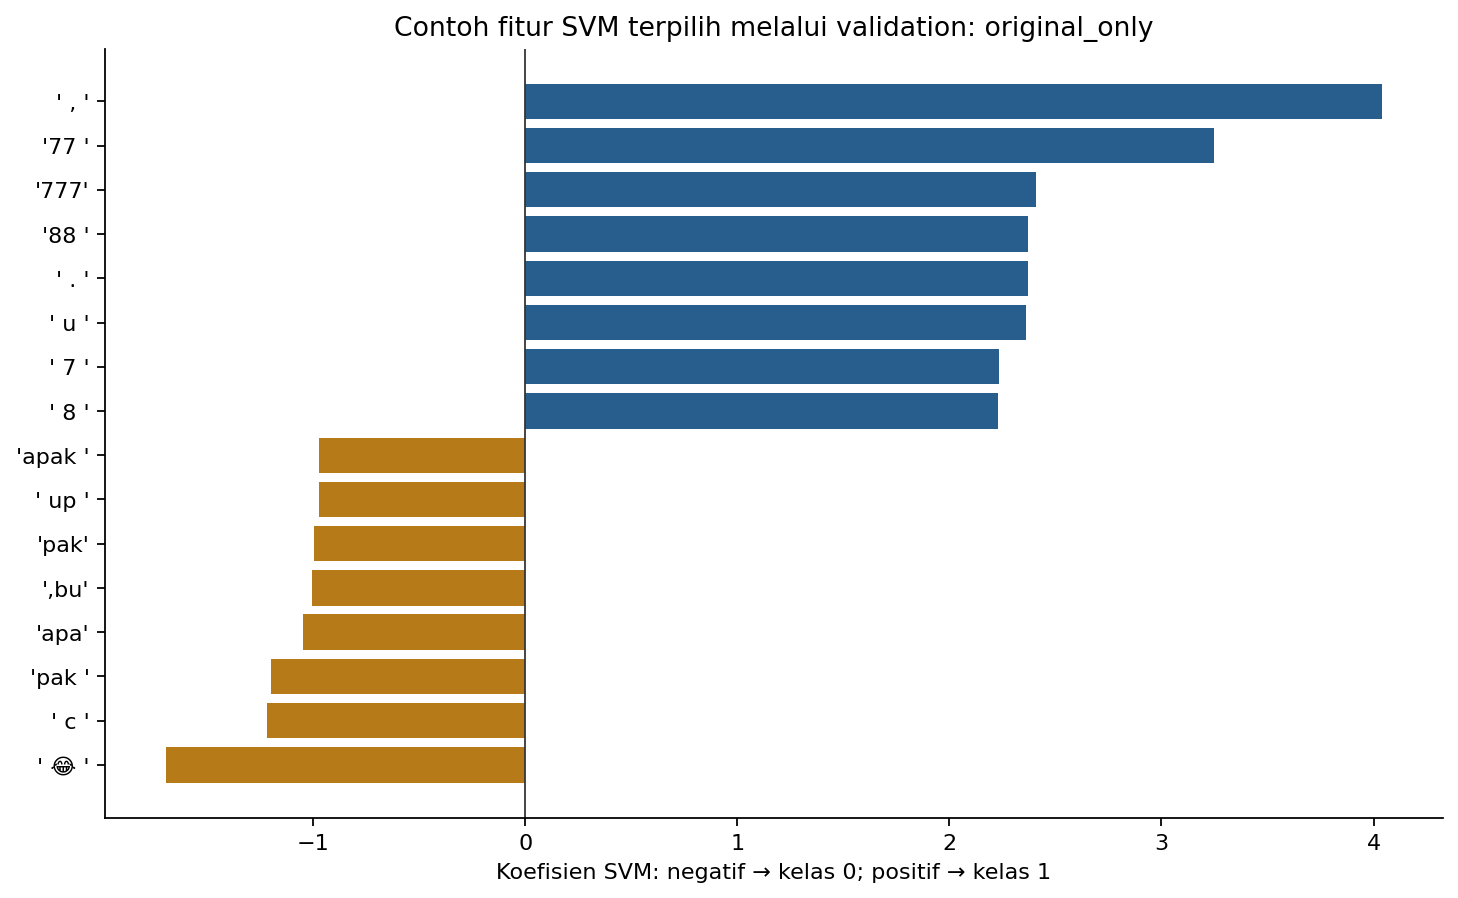

In [11]:
visible = pd.concat([feature_weights.nsmallest(8, 'coefficient_1_vs_0'),
                     feature_weights.nlargest(8, 'coefficient_1_vs_0')]).sort_values('coefficient_1_vs_0')
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.barh(np.arange(len(visible)), visible['coefficient_1_vs_0'],
        color=['#B77A18' if value < 0 else '#285E8E' for value in visible['coefficient_1_vs_0']])
ax.set_yticks(np.arange(len(visible)), labels=[repr(term) for term in visible['fitur']])
ax.axvline(0, color='#333333', linewidth=.8)
ax.set(xlabel='Koefisien SVM: negatif → kelas 0; positif → kelas 1',
       title=f'Contoh fitur SVM terpilih melalui validation: {selected_arm}')
fig.savefig(OUT_DIR / 'selected_model_features.png', dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(OUT_DIR / 'selected_model_features.png')))

## 10. Demo komentar baru

Pipeline tersimpan menerima teks yang sudah dibersihkan. Fungsi berikut menerapkan
cleaning yang sama dengan tahap persiapan JudiScope. Contoh buatan ini hanya demo;
hasilnya tidak masuk metrik test.

In [12]:
url_pattern = re.compile(r'(?:https?://|www\.)[^\s<>]+', re.IGNORECASE)

def clean_comment(text):
    text = unicodedata.normalize('NFKC', text)
    text = ''.join('' if unicodedata.category(c) == 'Cf' else c for c in text)
    text = ''.join(' ' if unicodedata.category(c) == 'Cc' else c for c in text)
    text = url_pattern.sub('<url>', text.lower())
    return re.sub(r'\s+', ' ', text).strip()

assert clean_comment('  𝐒𝐆𝐈𝟖𝟖  ') == 'sgi88'
assert clean_comment('cek HTTPS://contoh.test/a') == 'cek <url>'
assert original['komentar'].map(clean_comment).equals(original['komentar_processed'])
assert synthetic['komentar'].map(clean_comment).equals(synthetic['komentar_processed'])
demo = pd.DataFrame({'komentar': [
    'Videonya membantu, terima kasih bang',
    'depo receh di SITUSDEMO88, wd lancar',
    'Tolong hapus spam judi di komentar ini',
]})
demo['komentar_processed'] = demo['komentar'].map(clean_comment)
demo['prediksi'] = selected_model.predict(demo['komentar_processed'])
demo['decision_score'] = selected_model.decision_function(demo['komentar_processed'])
display(demo)

,komentar,komentar_processed,prediksi,decision_score
0,"Videonya membantu, terima kasih bang","videonya membantu, terima kasih bang",0,-0.919419
1,"depo receh di SITUSDEMO88, wd lancar","depo receh di situsdemo88, wd lancar",1,1.595100
2,Tolong hapus spam judi di komentar ini,tolong hapus spam judi di komentar ini,0,-0.960849


## 11. Periksa dan simpan artefak

Sebelum ekspor, metrik dihitung ulang dari confusion counts dan input diperiksa
agar tidak berubah. Kedua model disimpan lalu dimuat ulang untuk mencocokkan
prediksi dan margin. Model `.joblib` tetap lokal dan diabaikan Git; CSV, JSON,
grafik, dan notebook disertakan. Hanya muat model dari sumber yang dipercaya dan
gunakan versi scikit-learn yang sesuai dengan catatan eksperimennya.

In [13]:
def divide(a, b):
    return a / b if b else 0.0

for arm in SCENARIOS:
    tn, fp, fn, tp = np.asarray(matrices[arm]).ravel().tolist()
    independent = {
        'accuracy': (tn + tp) / len(test), 'precision_1': divide(tp, tp + fp),
        'recall_1': divide(tp, tp + fn), 'f1_1': divide(2 * tp, 2 * tp + fp + fn),
        'macro_f1': (divide(2 * tp, 2 * tp + fp + fn) + divide(2 * tn, 2 * tn + fp + fn)) / 2,
    }
    exported = test_results.loc[test_results['experiment'].eq(arm)].iloc[0]
    for name, value in independent.items():
        assert np.isclose(value, exported[name], rtol=0, atol=1e-12), (arm, name)
    assert test_predictions['source_row'].tolist() == test['source_row'].tolist()
    assert np.isfinite(margins[arm]).all()
assert len(test_predictions) == 1787 and test_predictions['source_row'].is_unique
assert test_predictions['label'].equals(test['label'])
assert {name: sha256_file(path) for name, path in INPUTS.items()} == input_hashes
assert json.dumps({'selected': selected_arm, 'best': best_per_arm}, sort_keys=True) == selection_before_test

for arm, model in final_models.items():
    path = OUT_DIR / f'svm_{arm}.joblib'
    joblib.dump(model, path, compress=3)
    restored = joblib.load(path)
    assert np.array_equal(restored.predict(test['komentar_processed']), predictions[arm])
    assert np.allclose(restored.decision_function(test['komentar_processed']), margins[arm], rtol=0, atol=1e-12)
    if arm == selected_arm:
        assert np.array_equal(restored.named_steps['tfidf'].get_feature_names_out(), terms)
        assert np.array_equal(restored.named_steps['svm'].coef_[0], coefficients)

tuning_results.to_csv(OUT_DIR / 'validation_results.csv', index=False)
test_results.to_csv(OUT_DIR / 'test_metrics.csv', index=False)
test_predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False, encoding='utf-8-sig')
errors.to_csv(OUT_DIR / 'selected_model_errors.csv', index=False, encoding='utf-8-sig')
feature_weights.to_csv(OUT_DIR / 'selected_model_feature_weights.csv', index=False, encoding='utf-8-sig')

summary = {
    'algorithm': 'Support Vector Machine (LinearSVC)', 'author': 'Aidan Ismail',
    'selection_metric': 'validation positive-class F1, then macro-F1', 'seed': SEED,
    'split_fractions': {'train': 0.6, 'validation': 0.2, 'test': 0.2},
    'original_rows': len(original), 'synthetic_train_rows': len(synthetic),
    'split_counts': {name: len(part) for name, part in parts.items()},
    'selected_experiment_before_test': selected_arm,
    'best_validation_per_experiment': list(best_per_arm.values()),
    'test_metrics': test_results.astype(object).where(test_results.notna(), None).to_dict(orient='records'),
    'classification_reports': reports, 'confusion_matrices': matrices,
    'versions': VERSIONS, 'source_sha256': {str(INPUTS[name].relative_to(PROJECT_DIR)): value
                                          for name, value in input_hashes.items()},
    'feature_settings': {'candidates': FEATURES, 'tfidf': TFIDF_OPTIONS},
    'classifier_settings': {'C_values': C_VALUES, **SVM_OPTIONS},
    'model_input': 'komentar_processed; fungsi clean_comment tersedia dalam notebook',
    'decision_score': 'uncalibrated signed margin; not a probability',
    'execution': {'mode': EXECUTION_MODE, 'started_at': STARTED_AT,
                  'selection_locked_at': selection_locked_at, 'test_evaluated_at': test_evaluated_at,
                  'completed_at': utc_now()},
    'verification': {'input_hashes_unchanged': True, 'selection_unchanged_after_test': True,
                     'all_candidates_converged': True, 'metrics_recomputed_from_counts': True,
                     'model_reload_predictions_and_margins_match': True},
    'final_model_details': {arm: {'feature_count': len(model.named_steps['tfidf'].vocabulary_),
                                'n_iter': int(np.max(model.named_steps['svm'].n_iter_))}
                            for arm, model in final_models.items()},
    'limitations': ['Definisi label dan proses anotasi sumber belum terverifikasi.',
                   'Split acak tingkat komentar bukan holdout video, kampanye, atau waktu.',
                   'Sintetis berbasis template bukan observasi YouTube independen.',
                   'Setiap konfigurasi akhir dilatih sekali; waktu bergantung perangkat dan lingkungan.',
                   'Versi library setiap metode dicatat terpisah; requirements.txt bukan lock hasil historis.'],
}
(OUT_DIR / 'experiment_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
assert len(pd.read_csv(OUT_DIR / 'test_predictions.csv')) == len(test)
print('Verifikasi dan ekspor SVM selesai:', OUT_DIR.relative_to(PROJECT_DIR))
print('Mode eksekusi:', EXECUTION_MODE)

Verifikasi dan ekspor SVM selesai: outputs\svm
Mode eksekusi: sequential_ipython


## 12. Ringkasan hasil

Skenario terpilih tetap mengikuti validation. Selisih skor pada satu split ini
bersifat deskriptif; notebook SVM tidak melakukan uji signifikansi atau memilih
parameter berdasarkan keluaran metode lain. Analisis pembandingan lintasmetode
dibahas terpisah dalam paper. Performa pada video atau kampanye baru belum diuji.

In [14]:
display(test_results[['experiment', 'accuracy', 'precision_1', 'recall_1', 'f1_1', 'macro_f1']].round(6))
delta_f1 = float(test_results.loc[test_results['experiment'].eq('with_synthetic'), 'f1_1'].iloc[0]
                 - test_results.loc[test_results['experiment'].eq('original_only'), 'f1_1'].iloc[0])
print('Pilihan validation:', selected_arm)
print(f'Perubahan F1 dengan sintetis: {delta_f1:+.6f} ({delta_f1 * 100:+.3f} poin persentase)')
print('Metrik dan input cocok; model tersimpan menghasilkan prediksi dan margin yang sama.')

Pilihan validation: original_only
Perubahan F1 dengan sintetis: -0.000852 (-0.085 poin persentase)
Metrik dan input cocok; model tersimpan menghasilkan prediksi dan margin yang sama.


,experiment,accuracy,precision_1,recall_1,f1_1,macro_f1
0,original_only,0.987689,0.996466,0.965753,0.980870,0.985897
1,with_synthetic,0.987129,0.994709,0.965753,0.980017,0.985263
2,majority_baseline,0.673195,0.000000,0.000000,0.000000,0.402341
